# Task 3 - Reproducible Data Analysis

**Project:** Procrastination Triggers in the Digital Environment  
**Authors:** Mashat Bekzhan, Nursultan Sultan

This notebook reproduces the Task 3 processing and statistical analysis from the raw JSONL file.

> **Transparency note:** the bundled records are synthetic pilot data used to validate the pipeline. They are not empirical findings about real students.


In [7]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from process_data import load_config, load_jsonl, analyze_dataframe
from visualize import create_figures

cfg = load_config(ROOT / "configs" / "task3_analysis_config.json")
np.random.seed(cfg["random_seed"])

print("Repository root:", ROOT)
print("Random seed:", cfg["random_seed"])
print("Bootstrap resamples:", cfg["bootstrap_resamples"])


Repository root: c:\Users\user\Downloads\procrastination-it-students
Random seed: 42
Bootstrap resamples: 5000


## 1. Data Ingestion

The raw JSONL file contains both practice/warm-up records and evaluation records. The `data_origin` field is retained so that the pilot dataset cannot be mistaken for real participant data.


In [8]:
raw = load_jsonl(ROOT / cfg["raw_data_path"])
display(raw.head())
print("Raw rows:", len(raw))
print("\nPhase counts:")
display(raw["phase"].value_counts().rename("rows").to_frame())
print("\nData origin:")
display(raw["data_origin"].value_counts().rename("rows").to_frame())


,participant_id,data_origin,phase,condition,run_order,task_id,completion_time_sec,accuracy_pct,cli,context_switches,procrastination_index,mental_fatigue,task_error
0,P01,synthetic_pilot,warmup,practice,0,W0,467.8,78.6,2.43,2,2.81,2.32,0
1,P01,synthetic_pilot,evaluation,focused,1,A,760.3,92.6,1.87,0,1.61,2.36,0
2,P01,synthetic_pilot,evaluation,interrupted,2,B,828.8,93.7,2.28,6,2.14,2.53,0
3,P02,synthetic_pilot,warmup,practice,0,W0,471.1,81.9,2.72,1,1.87,2.52,0
4,P02,synthetic_pilot,evaluation,focused,2,B,774.4,86.9,2.18,0,2.39,3.37,0


Raw rows: 90

Phase counts:


,rows
phase,
evaluation,60
warmup,30



Data origin:


,rows
data_origin,
synthetic_pilot,90


## 2. Warm-up Filtering and Guardrail Check

Warm-up rows are excluded from the main analysis. Task-error rows are counted as the guardrail metric and then excluded from the primary focused-vs-interrupted comparison.


In [9]:
warmup = raw[raw["phase"] == "warmup"].copy()
evaluation = raw[raw["phase"] == "evaluation"].copy()
clean = evaluation[evaluation["task_error"] == 0].copy()

error_rates = evaluation.groupby("condition")["task_error"].mean().mul(100)

print("Warm-up rows filtered:", len(warmup))
print("Evaluation rows before guardrail filtering:", len(evaluation))
print("Evaluation rows after guardrail filtering:", len(clean))
print("\nTask Error Rate (%):")
display(error_rates.round(2).rename("error_rate_pct").to_frame())


Warm-up rows filtered: 30
Evaluation rows before guardrail filtering: 60
Evaluation rows after guardrail filtering: 57

Task Error Rate (%):


,error_rate_pct
condition,
focused,3.33
interrupted,6.67


## 3. Statistical Aggregation

For every numeric metric, the pipeline reports mean, SD, median, p25, p75, p95, p99, and a bootstrapped 95% confidence interval around the median.


In [10]:
summary, task3_stats = analyze_dataframe(raw, cfg)

selected = summary[
    summary["metric"].isin(["cli", "completion_time_sec", "accuracy_pct", "context_switches"])
].copy()

display(
    selected[
        ["condition", "metric", "n", "mean", "sd", "median", "p25", "p75", "p95", "p99",
         "median_ci95_low", "median_ci95_high"]
    ].round(3)
)


,condition,metric,n,mean,sd,median,p25,p75,p95,p99,median_ci95_low,median_ci95_high
0,focused,cli,29,2.273,0.427,2.230,2.050,2.450,2.998,3.145,2.120,2.400
1,focused,completion_time_sec,29,709.997,72.624,695.200,659.100,749.300,833.400,885.992,671.700,742.100
2,focused,accuracy_pct,29,88.648,5.662,88.000,85.500,92.500,99.180,99.972,86.200,90.800
3,focused,context_switches,29,1.069,0.923,1.000,0.000,2.000,2.000,2.720,0.000,2.000
6,interrupted,cli,28,2.818,0.589,2.715,2.532,3.190,3.794,4.073,2.585,3.105
7,interrupted,completion_time_sec,28,789.125,115.173,801.000,730.275,846.075,957.040,1006.695,757.150,830.800
8,interrupted,accuracy_pct,28,86.525,7.895,87.700,78.900,93.475,97.100,97.903,82.700,91.050
9,interrupted,context_switches,28,5.643,2.264,6.000,3.750,7.000,9.000,9.730,4.000,7.000


## 4. Primary Paired CLI Comparison

Only participant codes with valid CLI measurements in both experimental conditions are included in the paired comparison. Normality is checked on the paired difference scores before the inferential test is selected.


In [11]:
stats_table = pd.DataFrame({
    "Statistic": [
        "Complete pairs",
        "Mean Delta CLI",
        "Median Delta CLI",
        "95% CI low",
        "95% CI high",
        "Cohen's dz",
        "Shapiro-Wilk p",
        "Selected test",
        "Test p-value",
    ],
    "Value": [
        task3_stats["complete_pairs_for_primary_cli"],
        round(task3_stats["delta_cli_mean"], 3),
        round(task3_stats["delta_cli_median"], 3),
        round(task3_stats["delta_cli_mean_ci95"][0], 3),
        round(task3_stats["delta_cli_mean_ci95"][1], 3),
        round(task3_stats["cohens_dz"], 3),
        round(task3_stats["normality_shapiro_p"], 4),
        task3_stats["inferential_test"],
        task3_stats["p_value_two_sided_or_test_default"],
    ]
})
display(stats_table)


,Statistic,Value
0,Complete pairs,27
1,Mean Delta CLI,0.515
2,Median Delta CLI,0.41
3,95% CI low,0.374
4,95% CI high,0.659
5,Cohen's dz,1.318
6,Shapiro-Wilk p,0.4418
7,Selected test,paired_t_test
8,Test p-value,0.0


## 5. Scientific Visualization and Export

The visualization module exports each figure to vector PDF and 300 DPI PNG. Axes include the measurement scale/unit, and 95% confidence intervals are shown explicitly.


reports\figures\fig1_cognitive_load_comparison.png
reports\figures\fig1_cognitive_load_comparison.pdf
reports\figures\fig2_completion_time_boxplot.png
reports\figures\fig2_completion_time_boxplot.pdf


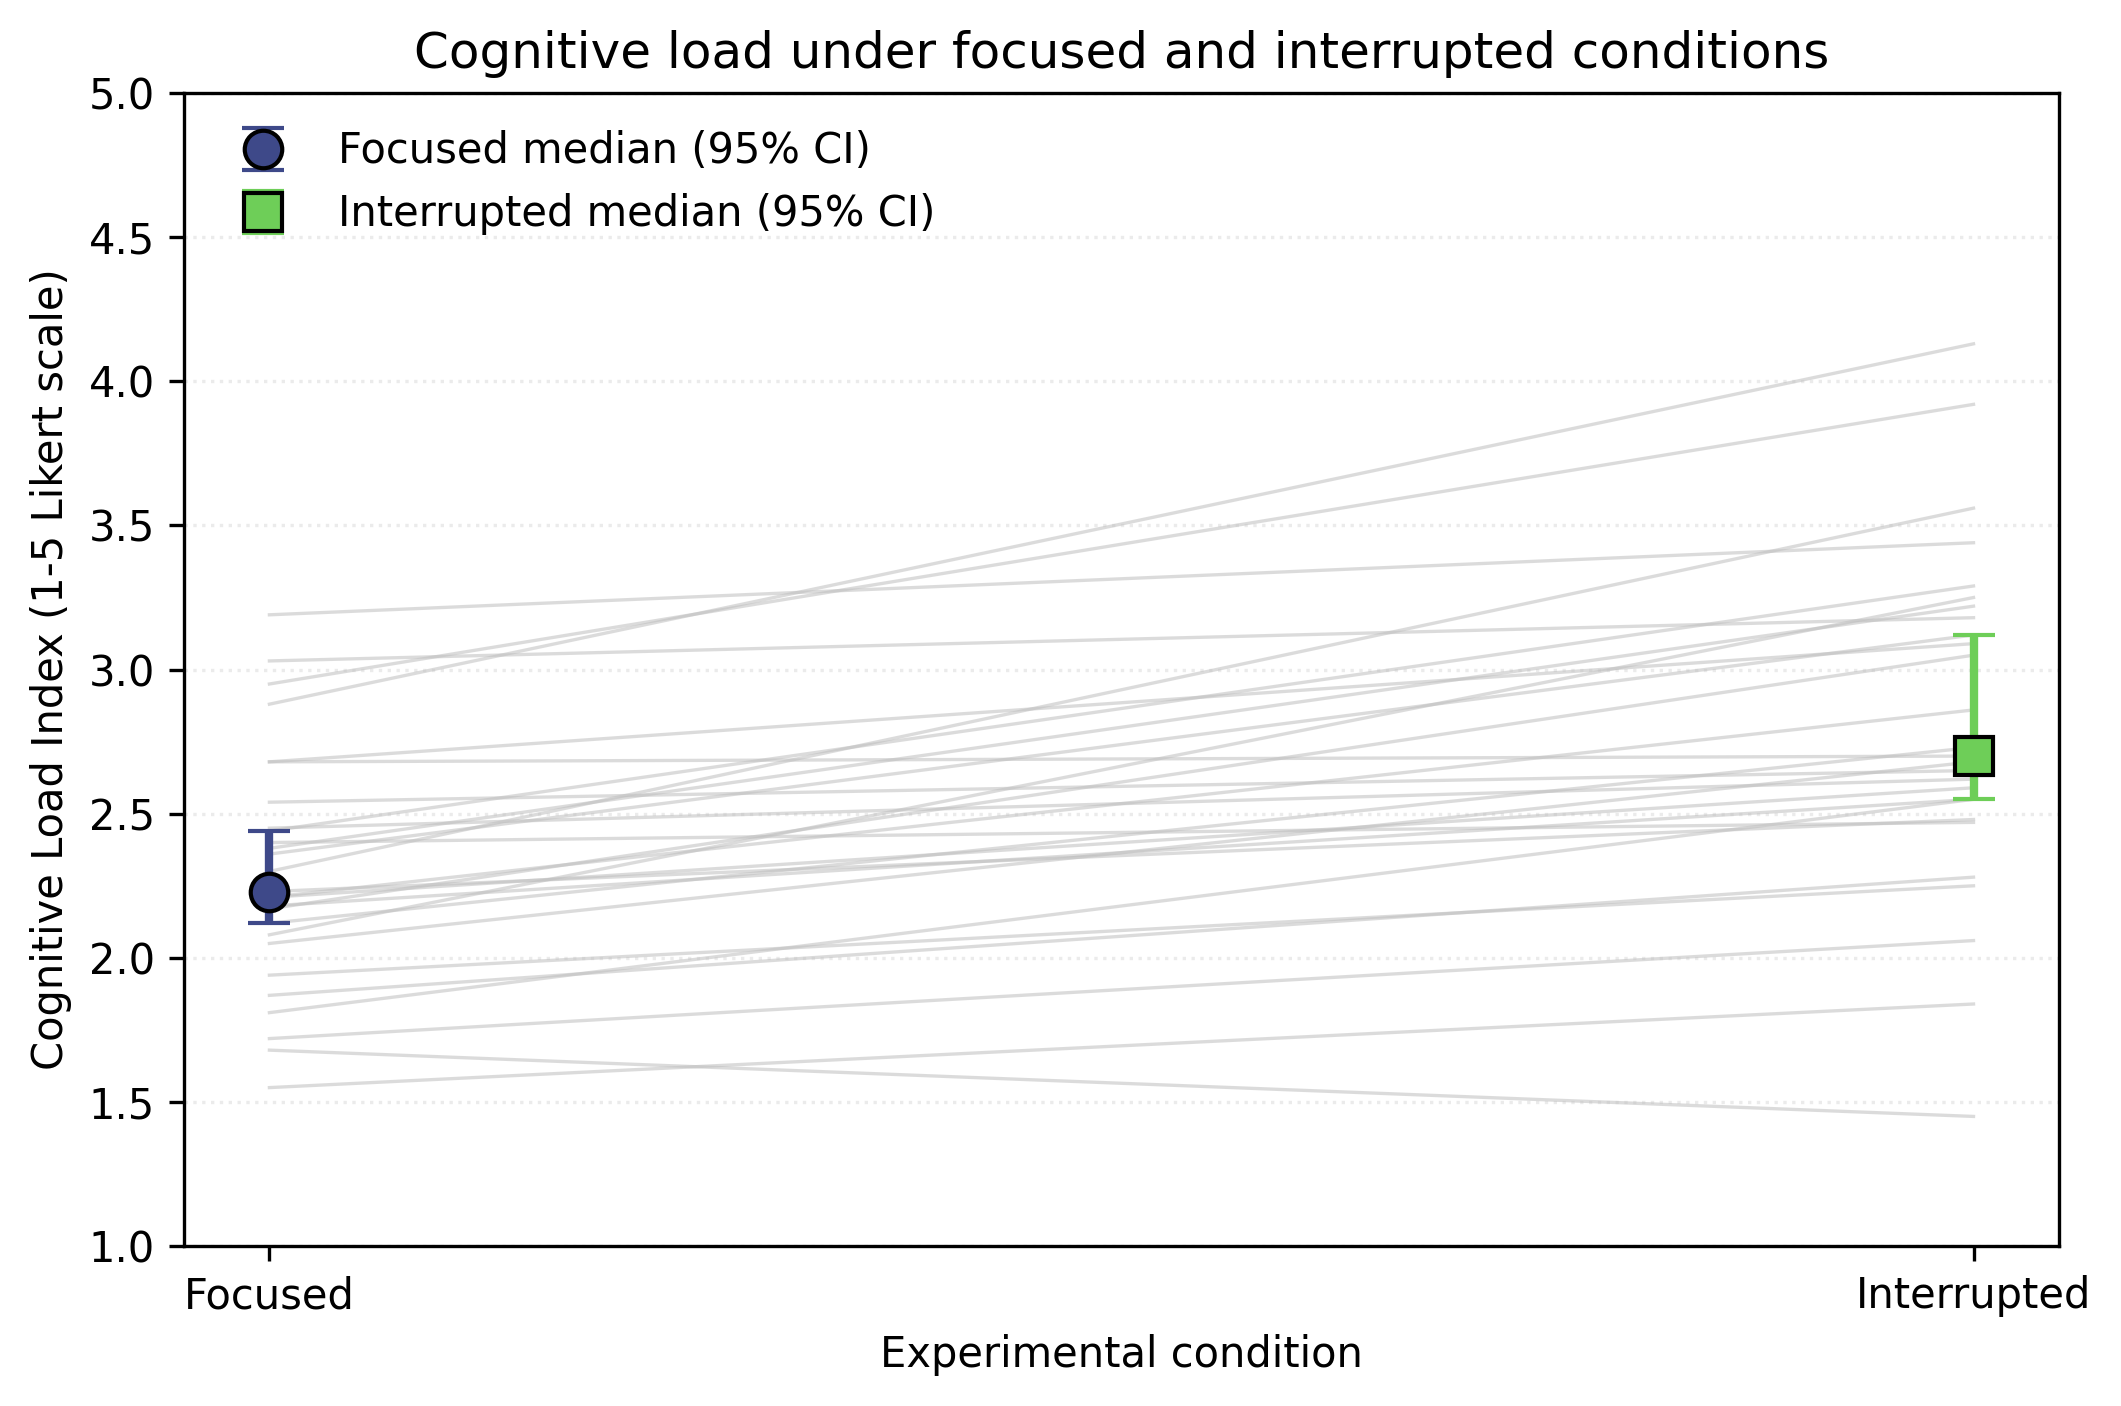

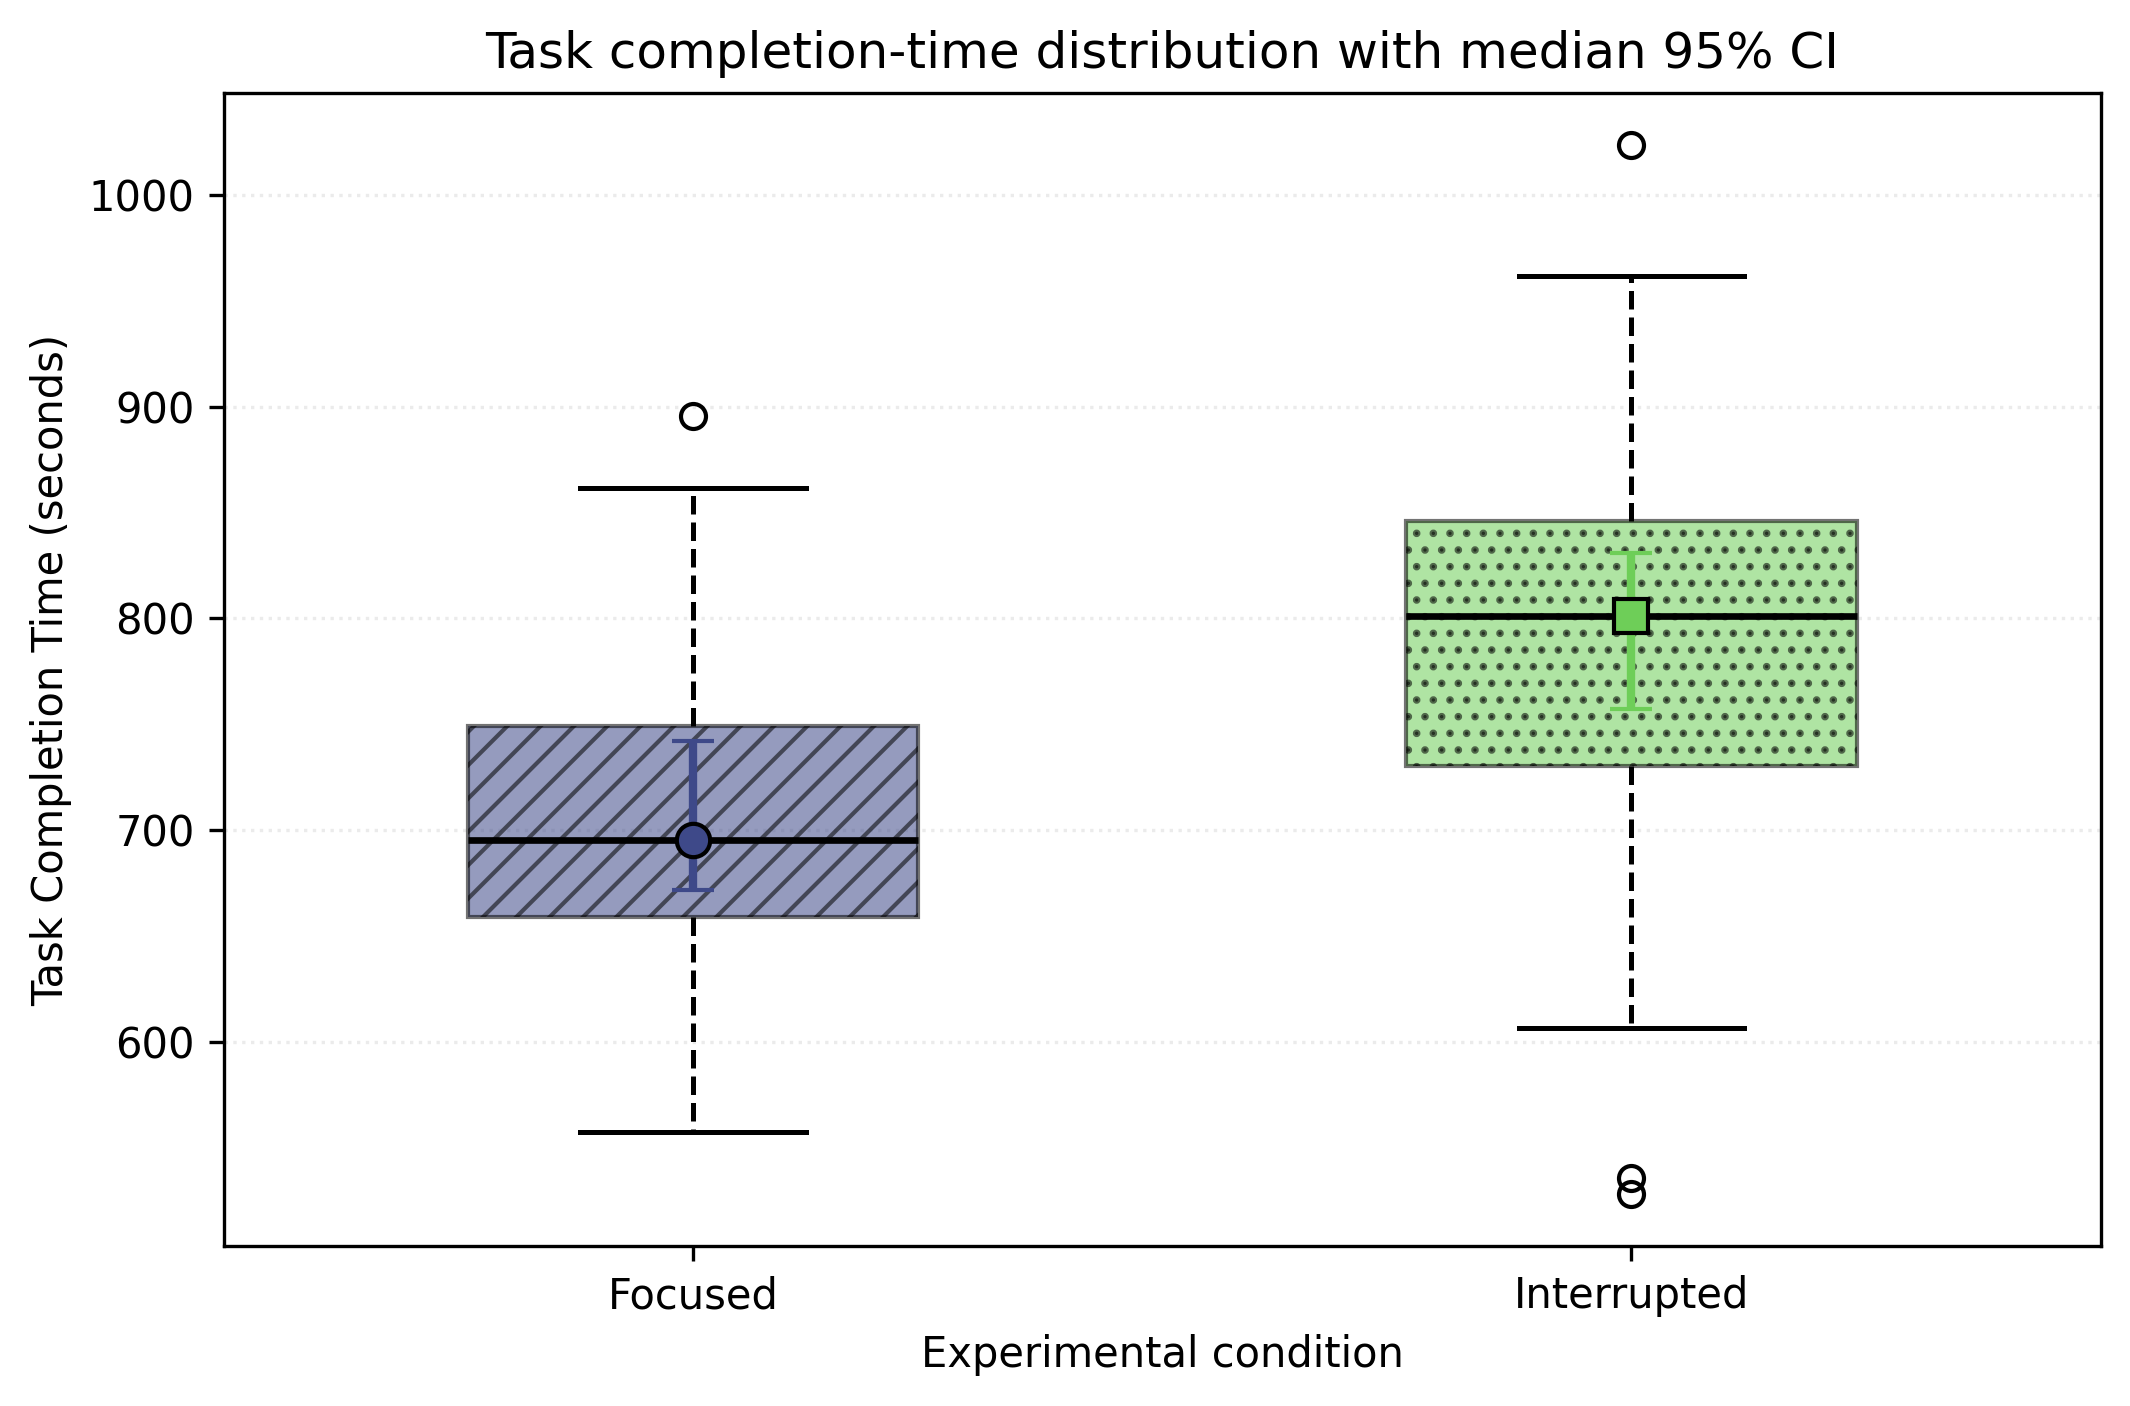

In [12]:
figure_paths = create_figures()
for p in figure_paths:
    print(p.relative_to(ROOT))

display(Image(filename=str(ROOT / "reports/figures/fig1_cognitive_load_comparison.png"), width=720))
display(Image(filename=str(ROOT / "reports/figures/fig2_completion_time_boxplot.png"), width=720))


## 6. Results Interpretation

For the **synthetic pilot**, the interrupted condition produces a higher CLI and longer completion time than the focused baseline. This pattern is intentionally used to exercise the statistical workflow and scientific plots.

It must **not** be presented as evidence that real IT students behave this way. A final empirical interpretation requires replacing the synthetic JSONL with anonymized Week 7-8 observations and rerunning the same notebook.


## 7. Limitations

1. The included dataset is synthetic, so substantive population-level conclusions are not valid.
2. The planned empirical study uses a relatively small convenience sample, limiting generalizability.
3. Self-reported CLI, fatigue, and procrastination measures may be affected by response bias.
4. Short controlled tasks may not fully represent long real-world study sessions.
5. Task errors are tracked separately and excluded from the primary comparison to avoid treating technical/protocol failures as valid performance measurements.
